In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# USE 20% DATASET FOR VALIDATION

## Regression - Facebook page dataset

In [ ]:
# data preparation
# sample training sets of 10,20,30,...

In [ ]:
#apply linear regression

In [ ]:
#calculate mse score

## Regression - News popularity in social media dataset

In [ ]:
# data preparation
# sample training sets of 10,20,30,...

In [ ]:
# apply linear regression

In [ ]:
# calculate mse score

## MSE plotting and comparison

In [ ]:
# code for showing the MSE score

#write text comparing both behaviours

## Quadratic regression - Facebook page dataset

## Quadratic regression - News popularity on social media dataset

## MSE plotting and comparison - quadratic regression

## Cross-validation between linear regression and quadratic regression

In [ ]:
#do the same as in regression but use logistic regression and logistic loss function

## Classification - Wine dataset

Import data

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine = fetch_ucirepo(id=109) 
  
# data (as pandas dataframes) 
X = wine.data.features 
y = wine.data.targets 
  
# check for missing values  
print(X.info()) 
  
# variable information 
print(wine.variables)


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
dtypes: float64(11), 

In [4]:
print(X.columns)

Index(['Alcohol', 'Malicacid', 'Ash', 'Alcalinity_of_ash', 'Magnesium',
       'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
       'Proanthocyanins', 'Color_intensity', 'Hue',
       '0D280_0D315_of_diluted_wines', 'Proline'],
      dtype='str')


Divide train+test sets

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [8]:
from sklearn.metrics import log_loss

sizes=[10, 20, 50, 100]
repeats=15
train_losses, val_losses = [], []


for s in sizes:
    tr, va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(
            X_train, y_train, train_size=s, random_state=r, stratify=y_train
        )

        model.fit(X_sample, y_sample)

        val_loss = model.predict_proba(X_test)
        tr.append(log_loss(y_sample, model.predict_proba(X_sample)))
        va.append(log_loss(y_test, val_loss))

    train_losses.append(np.mean(tr))
    val_losses.append(np.mean(va))

       

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

Plotting

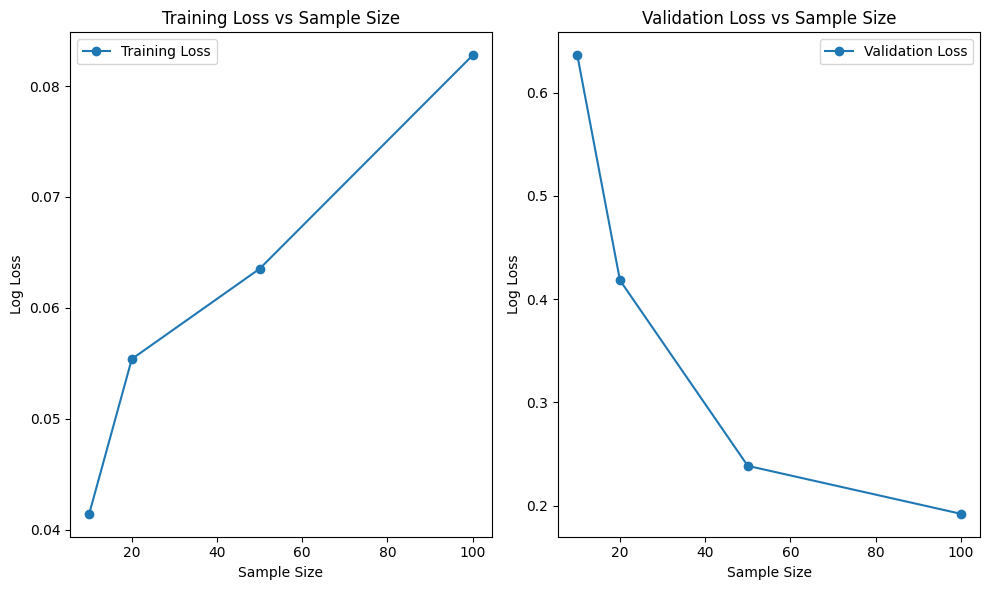

In [9]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_losses, label='Training Loss', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Log Loss')
ax1.set_title('Training Loss vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_losses, label='Validation Loss', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Log Loss')
ax2.set_title('Validation Loss vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()

Quadratic regression

In [13]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
import numpy as np

quad_loss = []
quad_val_loss = []
quad_model = make_pipeline(PolynomialFeatures(degree=2), LogisticRegression())

for s in sizes:
    q_tr, q_va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=s, random_state=r, stratify=y_train)
        
        quad_model.fit(X_sample, y_sample)    #fitting a linear model on the training data
        q_val_loss = quad_model.predict_proba(X_test)
        q_tr.append(log_loss(y_sample, model.predict_proba(X_sample)))
        q_va.append(log_loss(y_test, q_val_loss))

    quad_loss.append(np.mean(q_tr))
    quad_val_loss.append(np.mean(q_va))




c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

Cross-validation

In [16]:

from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score

log_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_log_loss')

quad_scores = cross_val_score(quad_model, X_train, y_train, cv=5, scoring='neg_log_loss')

log_cv_loss = -np.mean(log_scores)
quad_cv_loss = -np.mean(quad_scores)


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\va

## Classification - Online Retail dataset